# Ji et al. 2020 — Cutaneous SCC
## 05 · Hub module cross-repression

Gast **OR** pSom genes, hub (Mixed) cells → per-gene correlation to each module → mutual-correlation scatter. **Gate 3** tests whether Gast and pSom compete (negative mutual r) in the hub.

In [1]:
import os, sys, re, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import anndata as ad
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # Ji2020_Skin-2  (attempt suffix)
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition (Skin)
dset = re.sub(r'-\d+$', '', name)                       # strip -N attempt suffix -> input folder key
pth  = os.path.join(*([os.pardir] * 6))                 # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + dset)                                # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)            # h5ads
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
FEAT = os.path.join(pth_data, 'features', 'biomart')
print('dataset:', name, '| category:', cat)

dataset: Ji2020_Skin-2 | category: Skin


In [3]:
c_dict = {'Gast': plt.cm.tab20c(12), 'pSom': plt.cm.tab20c(8), 'Both': 'darkgrey'}

In [4]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
get_feat = lambda p: pd.read_csv(p).hsapiens.dropna()
gast = get_feat(os.path.join(FEAT, 'GSE162534.csv'))
psom = get_feat(os.path.join(FEAT, 'GSE229103.csv'))
g = pd.merge(gast, psom, 'outer').hsapiens.drop_duplicates()
g = g[g.isin(adata.var_names)]
adata_plt = adata[adata.obs.celltype == 'Mixed', g].copy()
print('Mixed hub cells:', adata_plt.n_obs, '| Gast|pSom genes:', g.size)

Mixed hub cells: 1513 | Gast|pSom genes: 139


### Per-gene module correlations, ranked

In [5]:
X = pd.DataFrame(adata_plt.X.toarray(), index=adata_plt.obs_names, columns=g)
X = X.loc[:, X.nunique(axis=0) > 1]
R = pd.DataFrame(index=X.columns)
R['Gast'] = pearsonr(X, adata_plt.obs.GSE162534.values[:, None], axis=0).statistic
R['pSom'] = pearsonr(X, adata_plt.obs.GSE229103.values[:, None], axis=0).statistic
rank = R.abs().sum(axis=1).rank(ascending=False)
R = R.loc[rank.sort_values().index].copy()
gast_s, psom_s = set(gast), set(psom); ix = R.index
msk_dict = {'Gast': ix.isin(gast_s) & ~ix.isin(psom_s),
            'pSom': ~ix.isin(gast_s) & ix.isin(psom_s),
            'Both': ix.isin(gast_s) & ix.isin(psom_s)}
for mod, msk in msk_dict.items():
    R.loc[msk, 'Module'] = mod; print(mod, int(msk.sum()))
R['Module'] = pd.Categorical(R.Module, list(reversed(list(msk_dict.keys()))), ordered=True)

Gast 48
pSom 60
Both 24


### Mutual correlation + permutation null — Gate 3
The Gast-gene and pSom-gene correlation vectors are mutually anti-correlated (**r < 0**), well below a per-cell-shuffle null → competitive cross-repression. **Gate 3 GO.**

In [6]:
rval = np.corrcoef(*R.loc[~msk_dict['Both'], ['Gast', 'pSom']].values.T)[0, 1].round(3)
print('hub r =', rval, '(anchor Puram -0.49)')
rng = np.random.default_rng(SEED); nulls = []
a_obs = R.loc[~msk_dict['Both'], 'Gast'].values
cols_nb = X.columns[~(X.columns.isin(gast_s) & X.columns.isin(psom_s))]
Xnb = X[cols_nb].values; mod2 = adata_plt.obs.GSE229103.values[:, None]
for _ in range(300):
    perm = rng.permutation(mod2.ravel())[:, None]
    bp = pearsonr(Xnb, perm, axis=0).statistic
    nulls.append(np.corrcoef(a_obs, bp)[0, 1])
nulls = np.array(nulls)
print('permutation null r = %.3f +/- %.3f (p = %.3f)' % (nulls.mean(), nulls.std(), (nulls <= rval).mean()))
print('VERDICT:', 'REAL cross-repression -> Gate 3 GO' if rval < nulls.mean() - 2*nulls.std() else 'within null -> NO-GO')

hub r = -0.473 (anchor Puram -0.49)
permutation null r = 0.006 +/- 0.092 (p = 0.000)
VERDICT: REAL cross-repression -> Gate 3 GO


### `modules.pdf` — mutual-correlation scatter

saved modules.pdf | hub r = -0.473


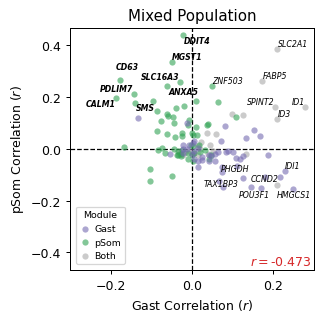

In [7]:
from adjustText import adjust_text
fig, ax = plt.subplots(1, 1, figsize=(3.5, 3.5))
for mod, sdf in R.groupby('Module', observed=True):
    sdf.plot(kind='scatter', x='Gast', y='pSom', color=c_dict[mod], label=mod, s=25, alpha=.6, linewidth=0, ax=ax)
ax.axvline(0, color='k', lw=1, ls='--', zorder=0); ax.axhline(0, color='k', lw=1, ls='--', zorder=0)
xlim = abs(np.asarray(ax.get_xlim())).max(); ylim = abs(np.asarray(ax.get_ylim())).max()
ax.set_xlim(-xlim, xlim); ax.set_ylim(-ylim, ylim)
n, texts = 20, []
for i in R.head(n).index:
    xi, yi = R.loc[i].Gast, R.loc[i].pSom
    fw = 'bold' if (xi < 0 and yi > 0) else 'normal'
    texts.append(ax.text(xi, yi, i, fontsize=6.25, fontstyle='italic', fontweight=fw))
adjust_text(texts=texts)
ax.legend(title='Module', loc='lower left', title_fontsize=7.5, handlelength=1,
          handletextpad=.5, borderaxespad=.65, fontsize=7.5, reverse=True)
ax.text(.99, .01, r'$r=$' + f'{rval}', transform=ax.transAxes, fontsize=10, color='tab:red', ha='right', va='bottom')
ax.set_title('Mixed Population'); ax.set_xlabel(r'Gast Correlation ($r$)'); ax.set_ylabel(r'pSom Correlation ($r$)')
fig.savefig(os.path.join(pth_fig, 'modules.pdf'), bbox_inches='tight'); plt.show()
print('saved modules.pdf | hub r =', rval)